# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


---

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings. 



In [2]:
# Import libraries
import pandas as pd
import numpy as np

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis

In [6]:
pd.set_option('display.max_columns', None)

In [9]:
amazon = pd.read_csv("C:\\Users\\durga\\Downloads\\amz_uk_price_prediction_dataset.csv.zip")

In [10]:
amazon.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [11]:
amazon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [13]:
amazon.describe(include ='all')

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
count,2.443651e+06,2443651,2443651,2.443651e+06,2.443651e+06,2.443651e+06,2443651,2.443651e+06,2443651
unique,NaN,2222742,2077591,NaN,NaN,NaN,2,NaN,296
top,NaN,B083L94P36,OYhmc Portable Pedal Exerc,NaN,NaN,NaN,False,NaN,Sports & Outdoors
freq,NaN,7,723,NaN,NaN,NaN,2435671,NaN,836265
mean,1.370545e+06,NaN,NaN,2.152836e+00,4.806278e+02,8.924381e+01,NaN,2.589699e+01,NaN
std,8.160562e+05,NaN,NaN,2.194865e+00,5.944124e+03,3.456089e+02,NaN,2.404837e+02,NaN
min,1.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.000000e+00,NaN
25%,6.589215e+05,NaN,NaN,0.000000e+00,0.000000e+00,9.990000e+00,NaN,0.000000e+00,NaN
50%,1.349029e+06,NaN,NaN,0.000000e+00,0.000000e+00,1.909000e+01,NaN,0.000000e+00,NaN
75%,2.060686e+06,NaN,NaN,4.400000e+00,5.900000e+01,4.599000e+01,NaN,0.000000e+00,NaN


In [14]:
#PART1 Finding Frequencies
category_counts = amazon['category'].value_counts()
category_counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [15]:
top_5_categories = category_counts.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [16]:
#Percentage Relative Frequencies
category_percentages = amazon['category'].value_counts(normalize=True) * 100
category_percentages.head(10)

category
Sports & Outdoors                         34.221949
Beauty                                     0.790293
Handmade Clothing, Shoes & Accessories     0.786896
Bath & Body                                0.781290
Birthday Gifts                             0.776625
Manicure & Pedicure Products               0.775070
Skin Care                                  0.768072
Make-up                                    0.767540
Hair Care                                  0.766681
Fragrances                                 0.759683
Name: proportion, dtype: float64

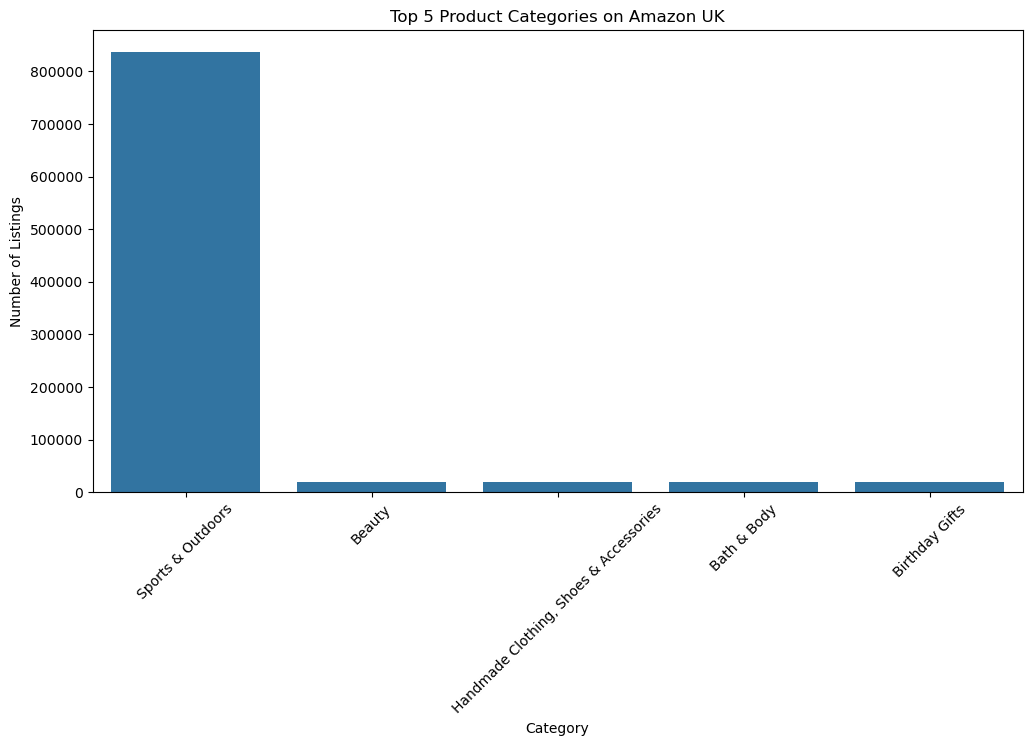

In [17]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=top_5_categories.index,
    y=top_5_categories.values
)

plt.title('Top 5 Product Categories on Amazon UK')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45)
plt.show()

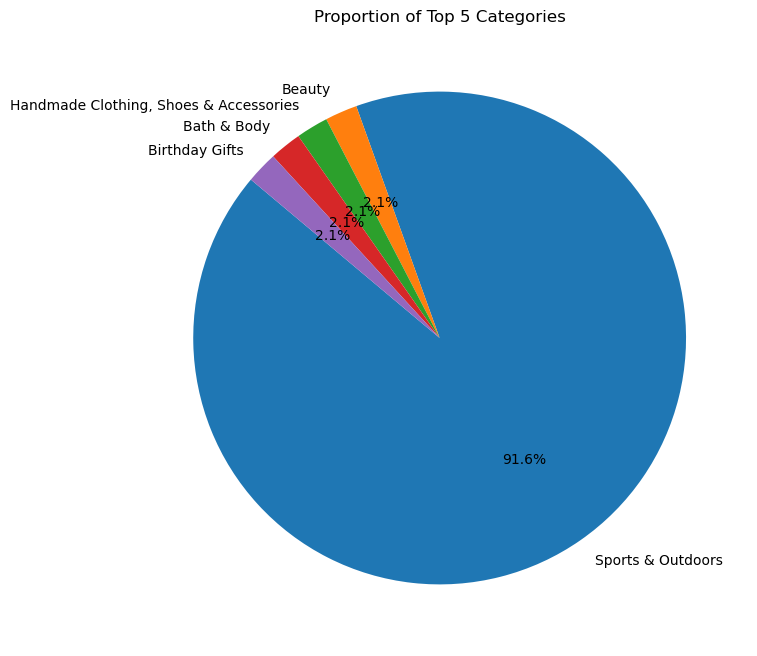

In [18]:
plt.figure(figsize=(8,8))

plt.pie(
    top_5_categories.values,
    labels=top_5_categories.index,
    autopct='%1.1f%%',
    startangle=140
)

plt.title('Proportion of Top 5 Categories')
plt.show()

In [20]:
#measures of centrality
#mean median mode
price_mean = amazon['price'].mean()
price_median = amazon['price'].median()
price_mode = amazon['price'].mode()

print('Mean Price:', price_mean)
print('Median Price:', price_median)
print('Mode Price:', price_mode)

Mean Price: 89.24380943923661
Median Price: 19.09
Mode Price: 0    9.99
Name: price, dtype: float64


In [21]:
#measures of Dispersion
price_variance = amazon['price'].var()
price_std = amazon['price'].std()
price_range = amazon['price'].max() - amazon['price'].min()

Q1 = amazon['price'].quantile(0.25)
Q3 = amazon['price'].quantile(0.75)
price_iqr = Q3 - Q1

print('Variance:', price_variance)
print('Standard Deviation:', price_std)
print('Range:', price_range)
print('Interquartile Range:', price_iqr)

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range: 36.0


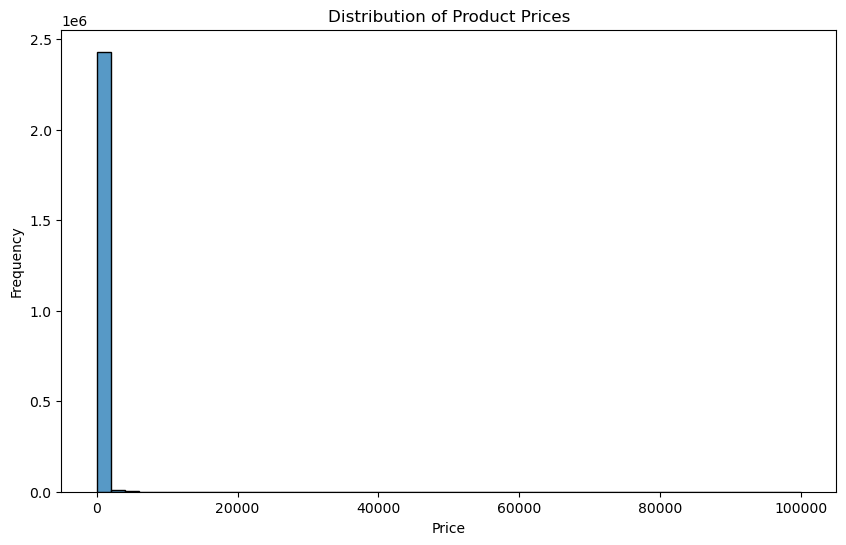

In [26]:
#Histogram based on prices
plt.figure(figsize=(10,6))

sns.histplot(amazon['price'], bins=50)

plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

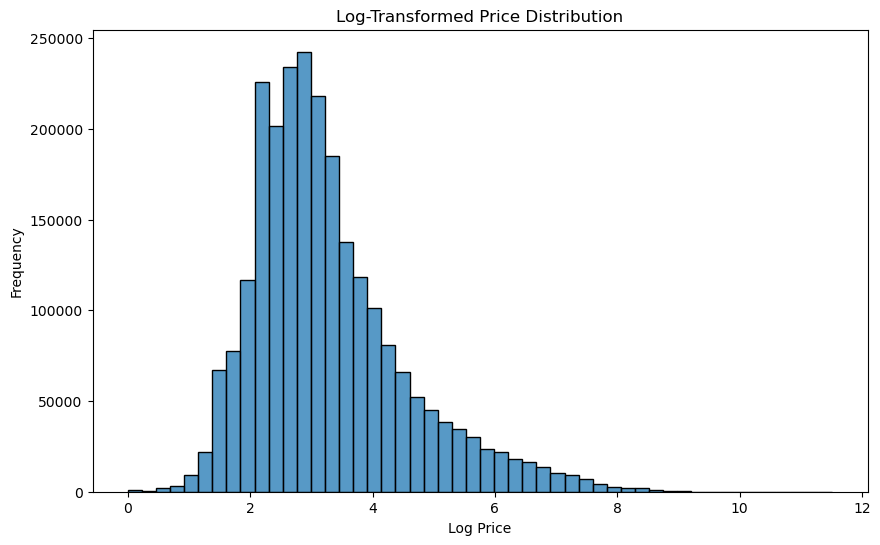

In [27]:
plt.figure(figsize=(10,6))

sns.histplot(np.log1p(amazon['price']), bins=50)

plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log Price')
plt.ylabel('Frequency')
plt.show()

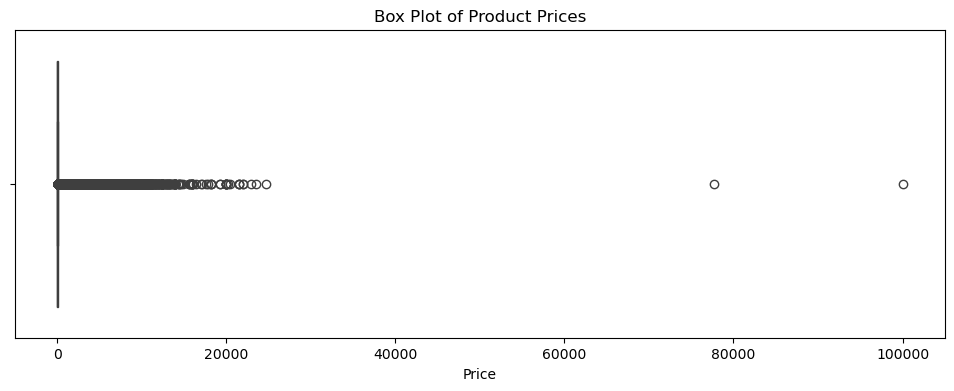

In [28]:
#Box Plot
plt.figure(figsize=(12,4))

sns.boxplot(x=amazon['price'])

plt.title('Box Plot of Product Prices')
plt.xlabel('Price')
plt.show()

In [31]:
#Unpacking Product Ratings
rating_mean = amazon['stars'].mean()
rating_median = amazon['stars'].median()
rating_mode = amazon['stars'].mode()[0]

print('Mean Rating:', rating_mean)
print('Median Rating:', rating_median)
print('Mode Rating:', rating_mode)

Mean Rating: 2.152836472966066
Median Rating: 0.0
Mode Rating: 0.0


In [30]:
amazon.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [33]:
#Measures of Dispersion
rating_variance = amazon['stars'].var()
rating_std = amazon['stars'].std()

rating_Q1 = amazon['stars'].quantile(0.25)
rating_Q3 = amazon['stars'].quantile(0.75)
rating_iqr = rating_Q3 - rating_Q1

print('Variance:', rating_variance)
print('Standard Deviation:', rating_std)
print('IQR:', rating_iqr)

Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
IQR: 4.4


In [34]:
#Skewness and Kurtosis
rating_skewness = skew(amazon['stars'].dropna())
rating_kurtosis = kurtosis(amazon['stars'].dropna())

print('Skewness:', rating_skewness)
print('Kurtosis:', rating_kurtosis)

Skewness: 0.08120730776283251
Kurtosis: -1.9260046425498398


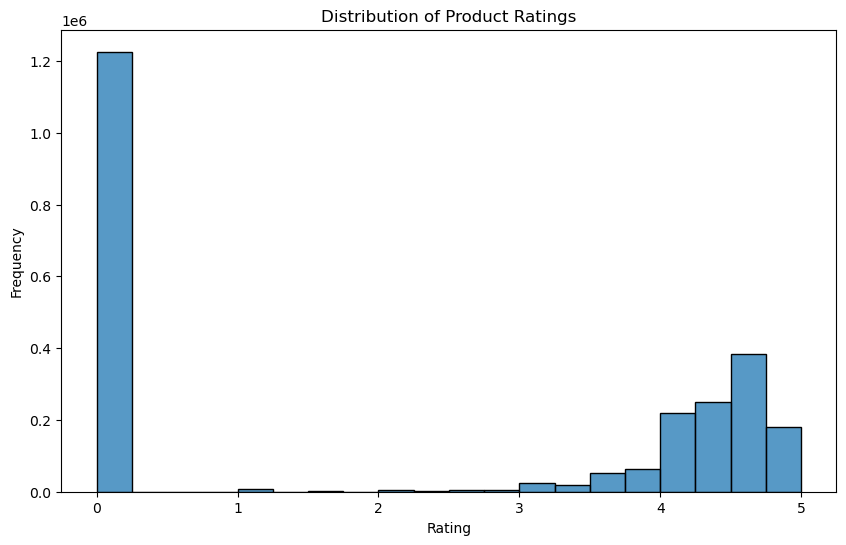

In [36]:
#Histogram
plt.figure(figsize=(10,6))

sns.histplot(amazon['stars'], bins=20)

plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()